## 0. Loading Packages

In [1]:
import pandas as pd
import numpy as np
import git
from pathlib import Path
import warnings
import os
import pickle
ROOT_DIR = Path(git.Repo('.', search_parent_directories=True).working_tree_dir)
os.chdir(os.path.join(ROOT_DIR, "utilities"))
from transform_audio import *
warnings.filterwarnings("ignore", category=UserWarning, module='numpy.lib.npyio')

## 1. Select transform type and group

In [2]:
DATASET_NAME = 'accent'
CATEGORY_NAME = 'gender'
GROUP_NAMES = ['male', 'female']
TRANSFORM_AFFIX = 'stft'
KS_THRESHOLD = 0.05

DATA_DIR = os.path.join(ROOT_DIR, 'raw-data', DATASET_NAME, 'transforms') 
COEFS_PATH = os.path.join(DATA_DIR, f'{TRANSFORM_AFFIX}_coefs.npz')
FREQS_PATH = os.path.join(DATA_DIR, f'{TRANSFORM_AFFIX}_freqs.npy')

OUTPUT_DIR = os.path.join(ROOT_DIR, 'transformed-data-audio', DATASET_NAME)
os.makedirs(OUTPUT_DIR, exist_ok=True)

csv_path = os.path.join(ROOT_DIR, 'raw-data', DATASET_NAME, f'full-{DATASET_NAME}.csv')
meta_df = pd.read_csv(csv_path)
gender_map = dict(zip(meta_df['filename'], meta_df['sex'].str.lower()))

print(f"Analysis: {CATEGORY_NAME.title()} ({GROUP_NAMES[0]} vs {GROUP_NAMES[1]}) | Threshold: {KS_THRESHOLD}")

Analysis: Gender (male vs female) | Threshold: 0.05


## 2. Banding comparison & export pickle files

In [3]:
def banding_distribution_comparison_pipeline(full_df, bands, band_type_name):
    print(f"\n" + "="*40)
    print(f"Pipeline for: {band_type_name.upper()} BANDS")
    print("="*40)
    
    # 1. KS Test
    comparison_df = compare_distributions_by_band(full_df, bands, CATEGORY_NAME, GROUP_NAMES)
    
    # 2. Subdivide data
    print(f"  - Subdividing data for Pickling...")
    subdivided_data = { "Original-Pitch": {} }
    for group_name in GROUP_NAMES:
        subgroup_df = full_df[full_df[CATEGORY_NAME] == group_name]
        subdivided_data["Original-Pitch"][group_name] = group_coeffs_by_group_band(subgroup_df, bands)
        
    # 3. Save to Pickle file
    filename = f'{DATASET_NAME}_oriPitch_{TRANSFORM_AFFIX}_{CATEGORY_NAME.replace(" ", "_")}_{band_type_name}.pickle'
    output_filepath = os.path.join(OUTPUT_DIR, filename)
    
    print(f"  - Saving to: {output_filepath} ...")
    with open(output_filepath, 'wb') as file:
        pickle.dump(subdivided_data, file)
        
    return comparison_df

  - Loading and combining data from: stft_coefs.npz
  - Concatenating all processed arrays...

Calculating Banding...


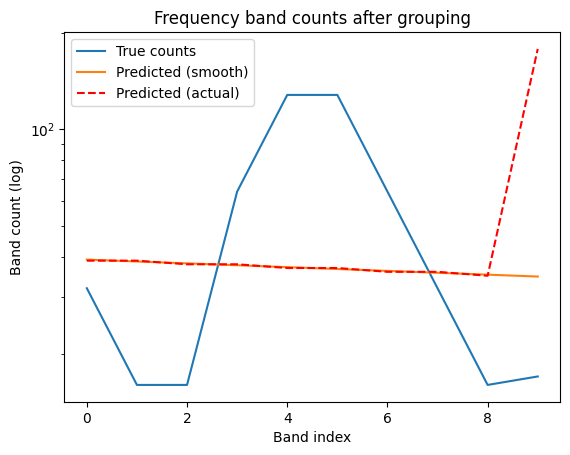

  - Raw Bands: 10 | Geometric Bands: 10

Pipeline for: RAW BANDS
  - Performing KS test band by band (male vs female)...
  - Subdividing data for Pickling...
  - Saving to: /Users/jiaxin/Documents/Summer 2025/hierarchical-bayesian-model-validation/transformed-data-audio/accent/accent_oriPitch_stft_gender_raw.pickle ...

Pipeline for: GEOMETRIC BANDS
  - Performing KS test band by band (male vs female)...
  - Subdividing data for Pickling...
  - Saving to: /Users/jiaxin/Documents/Summer 2025/hierarchical-bayesian-model-validation/transformed-data-audio/accent/accent_oriPitch_stft_gender_geometric.pickle ...

pipelines completed!


In [4]:
full_df = load_and_combine_data(COEFS_PATH, CATEGORY_NAME, GROUP_NAMES, gender_map)

print("\nCalculating Banding...")
unified_bands = freq_band_groupings(
    coefs_npz_path=COEFS_PATH,
    batch_size=None,
    subsample_every=100,
    ks_threshold=KS_THRESHOLD,
    max_depth=5,
    presplit_depth=1
)
geometric_bands = geometric_count_bands(unified_bands, visualize=True)
print(f"  - Raw Bands: {len(unified_bands)} | Geometric Bands: {len(geometric_bands)}")

results_raw = banding_distribution_comparison_pipeline(full_df, unified_bands, "raw")
results_geometric = banding_distribution_comparison_pipeline(full_df, geometric_bands, "geometric")

print("\npipelines completed!")

## 3. Visualize Results


############################################################
### Generating Analysis Report & Plots ###
############################################################

--- Results for: RAW BANDS Bands (male vs female) ---
In 10 bands, 0 have a difference greater than the threshold 0.05.
band_indices  ks_stat_real  ks_stat_imag
        0-31         0.039         0.039
       32-47         0.006         0.006
       48-63         0.007         0.007
      64-127         0.014         0.014
     128-255         0.014         0.014
     256-383         0.009         0.009
     384-447         0.010         0.010
     448-479         0.014         0.014
     480-495         0.013         0.013
     496-512         0.007         0.007


--- Results for: GEOMETRIC BANDS Bands (male vs female) ---
In 10 bands, 0 have a difference greater than the threshold 0.05.
band_indices  ks_stat_real  ks_stat_imag
        0-38         0.033         0.033
       39-77         0.006         0.006
      78-11

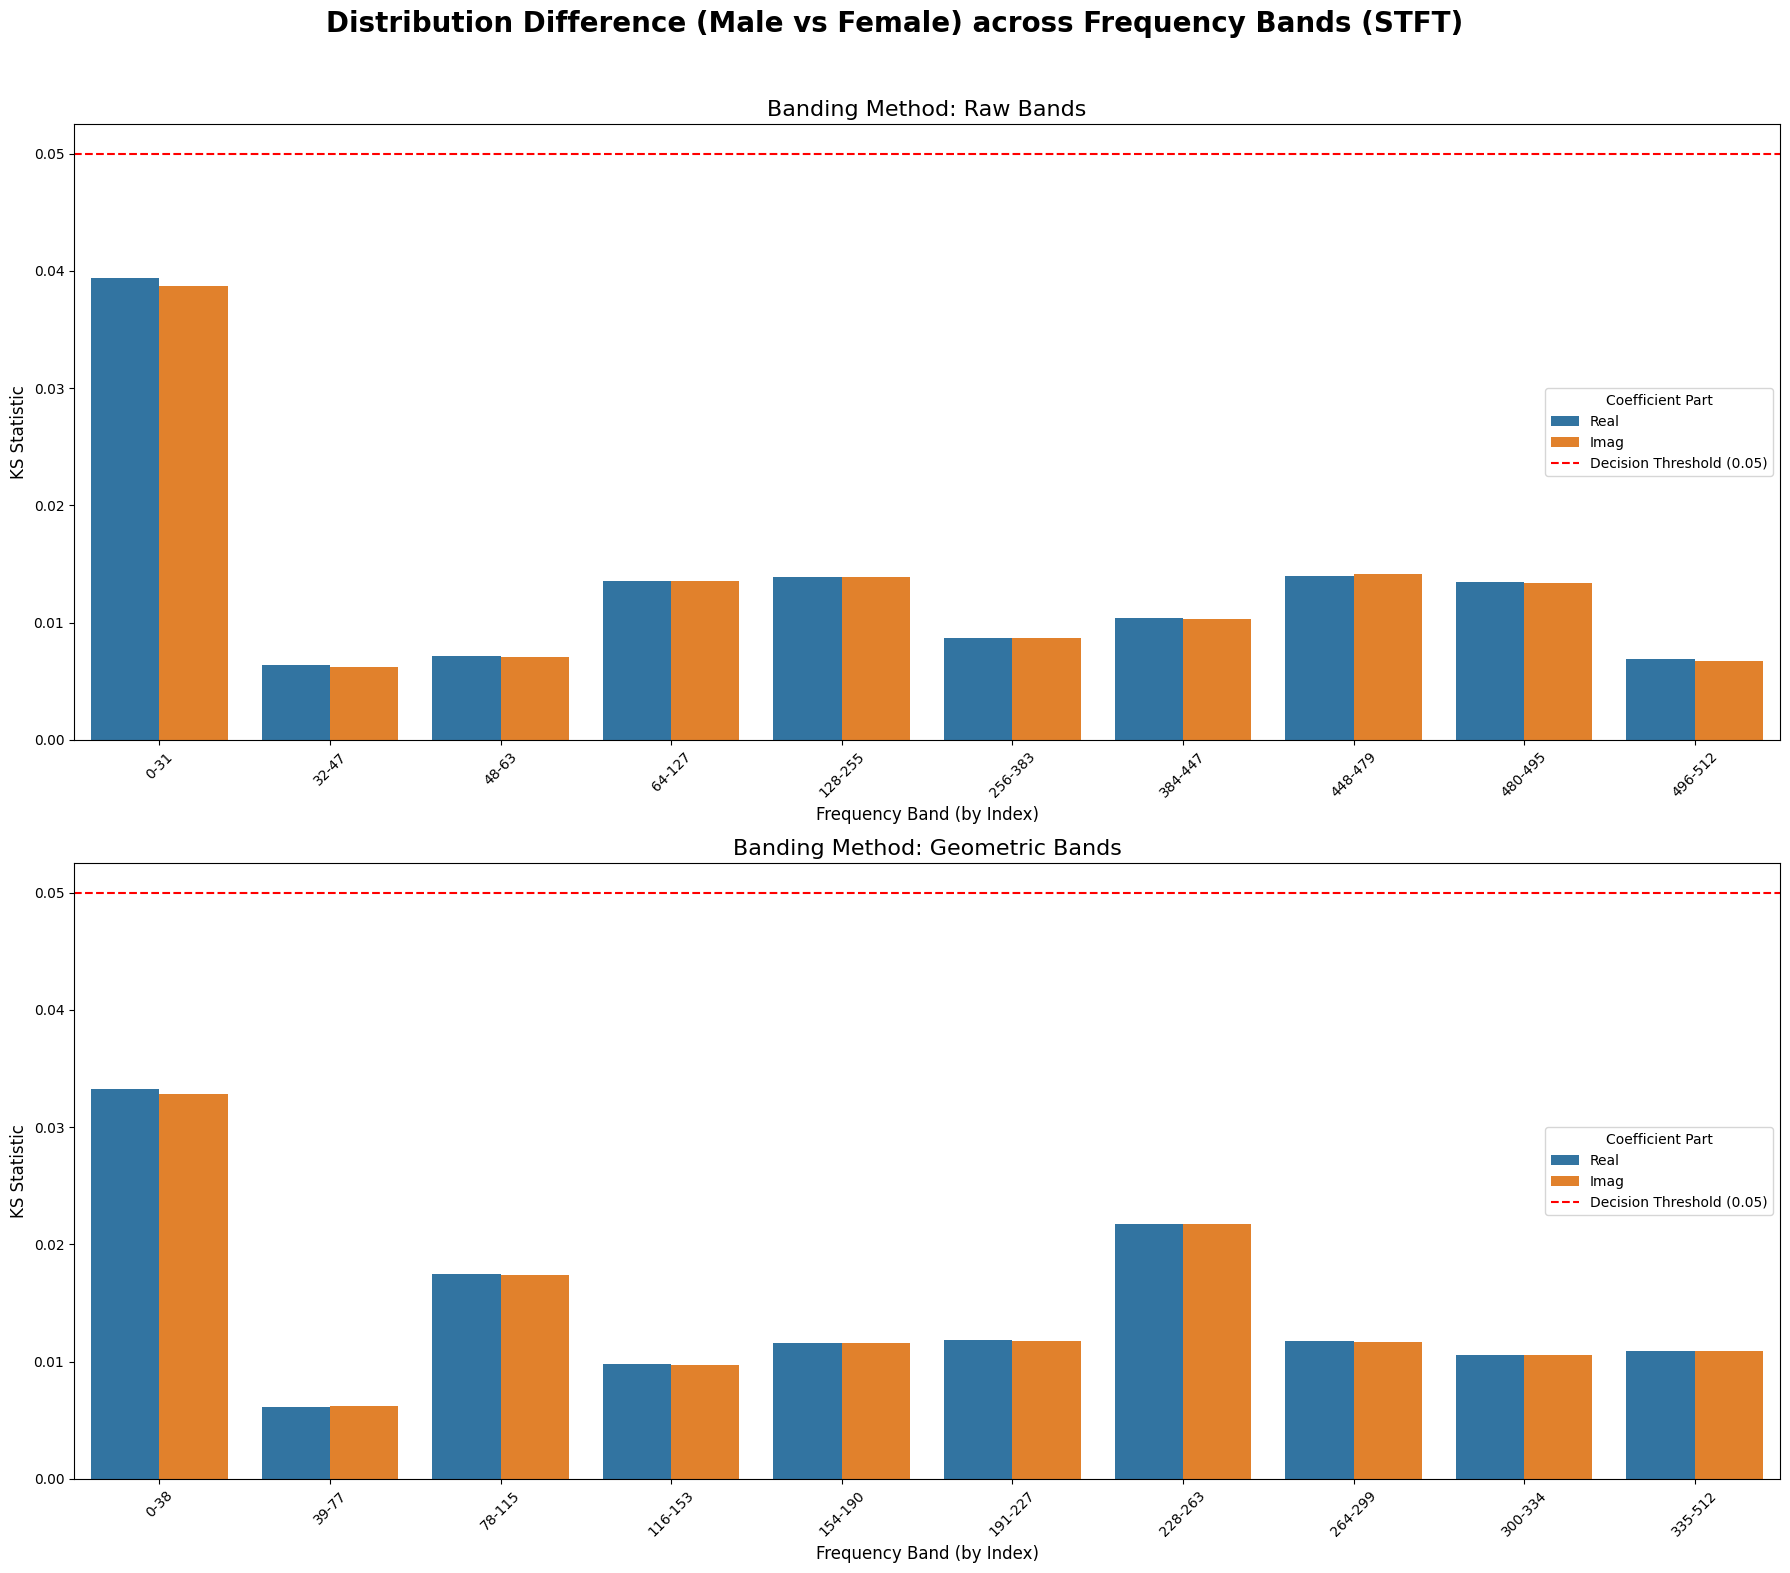

In [5]:
all_pipeline_results = {
    "Raw Bands": results_raw,
    "Geometric Bands": results_geometric
}

visualize_ks_group_distribution(
    results_dict=all_pipeline_results,
    group_names=GROUP_NAMES,
    transform_affix=TRANSFORM_AFFIX,
    ks_threshold=KS_THRESHOLD
)